### Load Libraries

In [ ]:
!pip install -r requirements.txt

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import warnings

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.linear_model import LassoCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from econml.dml import LinearDML
from dowhy import CausalModel

warnings.filterwarnings('ignore')
pd.options.mode.chained_assignment = None

### Pre-process dataset
- Fill missing values
- Create interest rate feature
- Create target loan acceptance

In [ ]:
raw = pd.read_csv("data/bank.csv", sep=';')

# Fill missing values
balance = pd.to_numeric(raw['balance'], errors='coerce').fillna(raw['balance'].median())
age = pd.to_numeric(raw['age'], errors='coerce').fillna(raw['age'].median())
duration = pd.to_numeric(raw['duration'], errors='coerce').fillna(raw['duration'].median())
loan_flag = (raw['loan'].astype(str).str.lower() == 'yes').astype(int)
housing_flag = (raw['housing'].astype(str).str.lower() == 'yes').astype(int)

# Create a synthetic continuous interest_rate (treatment)
np.random.seed(42)
month_map = {m:i for i, m in enumerate(['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec'])}
raw['month_ix'] = raw['month'].str.lower().map(month_map)
raw['month_ix'] = raw['month_ix'].fillna(raw['month_ix'].median())
base_rate = 4.5 + 0.05 * raw['month_ix']  # seasonal base
risk_addon = 0.003 * np.clip(2000 - balance, -2000, 2000) / 10.0  # lower balance => higher rate
risk_addon += 0.02 * loan_flag + 0.01 * housing_flag
risk_addon += 0.0008 * np.clip(age - 40, -40, 40)
rate_noise = np.random.normal(0, 0.4, len(raw))
interest_rate = (base_rate + risk_addon + rate_noise).clip(2.0, 15.0)
raw['interest_rate'] = interest_rate


# Encode job stability (rough scoring: admin/management good, student/unemployed lower)
job_map = {
    'admin.': 0.2,
    'management': 0.2,
    'blue-collar': 0.1,
    'technician': 0.15,
    'services': 0.1,
    'entrepreneur': 0.1,
    'housemaid': -0.05,
    'retired': -0.1,
    'student': -0.15,
    'unemployed': -0.2,
    'unknown': 0.0
}
raw['job_score'] = raw['job'].map(job_map).fillna(0)

# Numeric version of has_loan
raw['has_loan'] = (raw['loan'].astype(str).str.lower() == 'yes').astype(int) + (raw['housing'].astype(str).str.lower() == 'yes').astype(int)
raw['has_loan'] = raw['has_loan'].clip(0, 1)

# Define log-odds of acceptance (linear combination of features)
logit = (
    -0.25 * raw['interest_rate']              # higher rate → lower acceptance
    + 0.0002 * raw['balance'].clip(0, 20000)  # higher balance → higher acceptance
    + -0.01 * np.abs(raw['age'] - 40)         # peak at ~40 years
    + 2.0 * raw['job_score']                  # job stability effect
    - 0.5 * raw['has_loan']                   # penalty if already has a loan
    - 2.0                                    # intercept to control overall acceptance
)

# Convert logit to probability via sigmoid
raw['p_accept'] = 1 / (1 + np.exp(-logit))

# Sample binary outcome
np.random.seed(42)
raw['loan_accept'] = np.random.binomial(1, raw['p_accept'])

In [39]:
raw.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,...,pdays,previous,poutcome,y,month_ix,interest_rate,job_score,has_loan,p_accept,loan_accept
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,...,-1,0,unknown,0,4,4.880186,0.20,1,0.044301,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,...,-1,0,unknown,0,4,5.249194,0.15,1,0.028018,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,...,-1,0,unknown,0,4,5.582875,0.10,1,0.022636,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,...,-1,0,unknown,0,4,5.473012,0.10,1,0.031157,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,...,-1,0,unknown,0,4,5.200439,0.00,0,0.033249,0


### Define Confounders (X), Treatment (T) and Outcome (Y)

In [40]:
treatment_col = 'interest_rate'
outcome_col = 'loan_accept'

# select confounders based on domain knowledge (1st step of Feature Selection)
confounders_cols = ['age','job','marital','education','housing','loan', 'balance']

### Temporal Train/Test split
- Since we have temporal data, we must split based on date to avoid leakage
- Dataset is sorted by date already

In [95]:
train_df = raw[confounders_cols + [treatment_col, outcome_col]].iloc[:int(0.7*len(raw)), :]
test_df = raw[confounders_cols + [treatment_col, outcome_col]].iloc[int(0.7*len(raw)):, :]

### Categorical treatment

In [96]:
cat_cols = [c for c in confounders_cols if raw[c].dtype == 'object']
num_cols = [c for c in confounders_cols if c not in cat_cols] + [treatment_col]

preprocess = ColumnTransformer(
    transformers=[
        ('cat', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
        ('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))]), num_cols)
    ]
)

# Fit transformer on train
preprocess.fit(train_df[confounders_cols+[treatment_col]])

X_train = preprocess.transform(train_df[confounders_cols+[treatment_col]])
X_test = preprocess.transform(test_df[confounders_cols+[treatment_col]])

Y_train = train_df[outcome_col].values
Y_test = test_df[outcome_col].values

### Checking Positivity Violations in Interest Rate

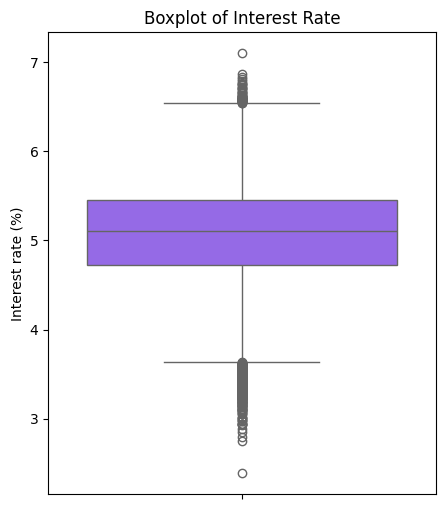

In [54]:
plt.figure(figsize=(5,6))
sns.boxplot(raw['interest_rate'], color='#8e55fb')
plt.ylabel('Interest rate (%)')
plt.title('Boxplot of Interest Rate')
plt.show()

### Create Dose-Response Curve

In [88]:
slearner = GradientBoostingClassifier(n_estimators=200, random_state=42)
slearner.fit(X_train, Y_train)

X_test_rate = pd.DataFrame(X_test, columns=preprocess.get_feature_names_out()).copy()

rates = np.linspace(2, 10.0, 25)
preds = []
for r in rates:
    X_test_rate[f'num__{treatment_col}'] = r
    preds.append(np.mean(slearner.predict_proba(X_test_rate)[:,1]))

print('Quick S-learner dose-response (rates -> predicted acceptance):')
for r,p in zip(rates, preds):
    print(f"{r:.2f}% -> {p:.3f}")

Quick S-learner dose-response (rates -> predicted acceptance):
2.00% -> 0.525
2.33% -> 0.525
2.67% -> 0.525
3.00% -> 0.409
3.33% -> 0.296
3.67% -> 0.085
4.00% -> 0.058
4.33% -> 0.052
4.67% -> 0.054
5.00% -> 0.050
5.33% -> 0.049
5.67% -> 0.037
6.00% -> 0.044
6.33% -> 0.028
6.67% -> 0.029
7.00% -> 0.029
7.33% -> 0.029
7.67% -> 0.029
8.00% -> 0.029
8.33% -> 0.029
8.67% -> 0.029
9.00% -> 0.029
9.33% -> 0.029
9.67% -> 0.029
10.00% -> 0.029


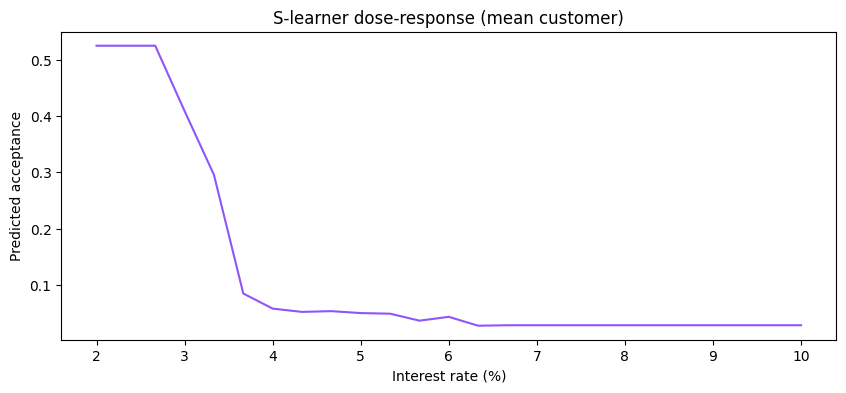

In [89]:
plt.figure(figsize=(10,4))
plt.plot(rates, preds, color='#8e55fb')
plt.xlabel('Interest rate (%)')
plt.ylabel('Predicted acceptance')
plt.title('S-learner dose-response (mean customer)')
plt.show()

### Handling Positivity Violations
- remove obervarions with lower interest rate than 4% and higher than 8% which is roughly ~30% of the data


In [97]:
X_train = pd.DataFrame(X_train, columns=preprocess.get_feature_names_out())
X_train[outcome_col] = Y_train
X_train = X_train[(X_train['num__interest_rate'] > 4) & (X_train['num__interest_rate'] < 8)]
Y_train = X_train[outcome_col]
X_train = X_train.drop(columns=[outcome_col])


In [98]:
slearner = GradientBoostingClassifier(n_estimators=200, random_state=42)
slearner.fit(X_train, Y_train)

X_test_rate = pd.DataFrame(X_test, columns=preprocess.get_feature_names_out()).copy()
X_test_rate = X_test_rate[(X_test_rate['num__interest_rate'] > 4) & (X_test_rate['num__interest_rate'] < 8)]

rates = np.linspace(2, 10.0, 25)
preds = []
for r in rates:
    X_test_rate[f'num__{treatment_col}'] = r
    preds.append(np.mean(slearner.predict_proba(X_test_rate)[:,1]))

print('Quick S-learner dose-response (rates -> predicted acceptance):')
for r,p in zip(rates, preds):
    print(f"{r:.2f}% -> {p:.3f}")

Quick S-learner dose-response (rates -> predicted acceptance):
2.00% -> 0.079
2.33% -> 0.079
2.67% -> 0.079
3.00% -> 0.079
3.33% -> 0.079
3.67% -> 0.079
4.00% -> 0.079
4.33% -> 0.042
4.67% -> 0.050
5.00% -> 0.046
5.33% -> 0.047
5.67% -> 0.034
6.00% -> 0.038
6.33% -> 0.025
6.67% -> 0.025
7.00% -> 0.025
7.33% -> 0.025
7.67% -> 0.025
8.00% -> 0.025
8.33% -> 0.025
8.67% -> 0.025
9.00% -> 0.025
9.33% -> 0.025
9.67% -> 0.025
10.00% -> 0.025


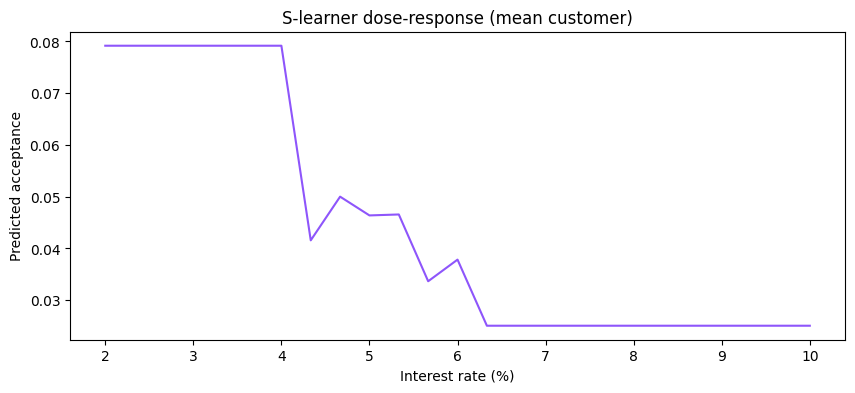

In [99]:
plt.figure(figsize=(10,4))
plt.plot(rates, preds, color='#8e55fb')
plt.xlabel('Interest rate (%)')
plt.ylabel('Predicted acceptance')
plt.title('S-learner dose-response (mean customer)')
plt.show()

### Calculate Marginal Effect
- LinearDML estimates the causal effect of a 1 percentage point increase in interest rate on acceptance, controlling for confounders (age, balance, etc.).
- For example, -0.0075 means: on average, increasing interest rate by 1pp reduces acceptance probability by 0.75 percentage points, holding other factors constant.
- This is the causal elasticity of acceptance with respect to interest rates. 

In [101]:
X_train = pd.DataFrame(X_train, columns=preprocess.get_feature_names_out())
T_train = X_train[['num__interest_rate']]
X_train = X_train.drop(columns=['num__interest_rate'])
X_test = pd.DataFrame(X_test, columns=preprocess.get_feature_names_out())
T_test = X_test[['num__interest_rate']]
X_test = X_test.drop(columns=['num__interest_rate'])


In [80]:
# Quick causal estimate with LinearDML (EconML)
model_y = GradientBoostingRegressor(random_state=42)
model_t = LassoCV()
est = LinearDML(model_y=model_y, model_t=model_t, discrete_treatment=False, random_state=42)
est.fit(Y_train, T_train, X=X_train)
theta = est.effect(X_test)
print('\nMean marginal effect dY/dT (LinearDML):', float(np.mean(theta)))

# Estimate acceptance & profit change for +1pp
mean_theta = float(np.mean(theta))
d_accept = mean_theta * 1.0  # per 1 percentage point
print(f"Approx change in acceptance probability for +1pp: {d_accept:.4f}")


Mean marginal effect dY/dT (LinearDML): -0.007567805091998462
Approx change in acceptance probability for +1pp: -0.0076


### Calculate Model performance
- Helps understanding how confident we are with the marginal effect

In [81]:
model = GradientBoostingClassifier(random_state=42)
model.fit(X_train, Y_train)
t_pred = model.predict_proba(X_test)[:,1]


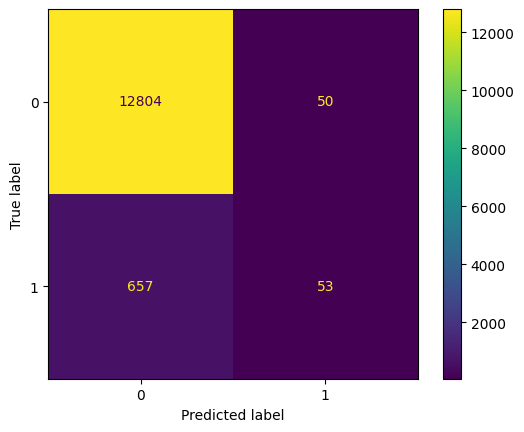

In [83]:
cm = confusion_matrix(Y_test, t_pred>0.5)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()


### Check if Model is capturing true causal effects
1. Key Numbers
-	Estimated effect: This is the effect of your original treatment (interest rate) on acceptance probability from the original model.
-	New effect: After randomly permuting interest_rate (placebo), the effect is essentially zero (0.00005).
-	p-value: 0.48 → not significant.

2. Meaning
- The placebo refutation tests whether the model would find an effect if there were no causal link.
- Since the placebo effect is near zero and not significant (p>0.05), it supports the credibility of your original causal estimate.
- In other words: your LinearDML estimate (dY/dT ≈ -0.0076) is unlikely to be a spurious correlation.


In [65]:
# Prepare data
causal_df = raw[['interest_rate','loan_accept','age', 'job', 'marital', 'education', 'housing', 'loan', 'balance']].rename(
    columns={'interest_rate':'T','loan_accept':'Y','age':'X1','job':'X2','marital':'X3','education':'X4','housing':'X5','loan':'X6','balance':'X7'}
)

# Specify model without graph string
model = CausalModel(
    data=causal_df,
    treatment='T',
    outcome='Y',
    common_causes=['X1','X2','X3','X4','X5','X6','X7']  # manual confounders
)

# Identify effect (backdoor adjustment)
identified_estimand = model.identify_effect()
print("\nDoWhy identified estimand:\n", identified_estimand)

estimate = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.econml.dml.LinearDML",
    method_params={
        'init_params': {
            'model_y': GradientBoostingRegressor(),
            'model_t': LassoCV(),
            'discrete_treatment': False
        },
        'fit_params': {}
    }
)
print("\nEstimated effect:", estimate.value)

# Refutation (placebo treatment)
ref = model.refute_estimate(
    identified_estimand,
    estimate,
    method_name="placebo_treatment_refuter",
    placebo_type="permute",
    num_simulations=5
)
print("\nRefutation result:\n", ref)


DoWhy identified estimand:
 Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
 d                             
────(E[Y|X4,X2,X3,X1,X7,X5,X6])
d[T]                           
Estimand assumption 1, Unconfoundedness: If U→{T} and U→Y then P(Y|T,X4,X2,X3,X1,X7,X5,X6,U) = P(Y|T,X4,X2,X3,X1,X7,X5,X6)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
 d                             
────(E[Y|X4,X2,X3,X1,X7,X5,X6])
d[T]                           
Estimand assumption 1, Unconfoundedness: If U→{T} and U→Y then P(Y|T,X4,X2,X3,X1,X7,X5,X6,U) = P(Y|T,X4,X2,X3,X1,X7,X5,X6)


Estimated effect: -0.0103402853472563

Refutation result:
 Refute: Use a Placebo Treatment
Estimated effect:-0.0103402853472563
New effect:5.473016364737804e-05
p value:0.4812716881622008

